# El toyset — figuras y tablas

Esto **no entrena**: lee lo que `Toyset_Generator.ipynb` dejó en
`CREDA/Results/tesis/toyset/` y dibuja. Retocar un color, un límite o una
etiqueta cuesta segundos; antes costaba el barrido entero.

Para actualizar los números hay que correr el generador. Para actualizar las
figuras, basta este cuaderno.

## Dónde está el repositorio

In [1]:
#!/usr/bin/env python3
"""The first code cell of every notebook a job may run — copied byte for byte.

One question, answered once: WHERE IS THE REPOSITORY THIS NOTEBOOK RUNS
AGAINST. Every later cell reads `ROOT` and none of them asks again.

Opened by a person on their own machine, this answers it exactly the way
these notebooks always have. A notebook lives at `<repo>/<Name>/Notebooks/`,
so the repository is two directories above the working directory. Nothing was
handed over, nothing is checked, and the behaviour is unchanged.

Started by a runner on a remote worker, it does not answer it by looking
around. The runner exports the directory it cloned the pinned commit into and
the commit it pinned; this cell reads both, and PROVES the checkout is at that
commit before returning it.

Guessing is the whole reason this cell exists. Under the runner the kernel's
working directory is the runner's own and the clone sits one level inside it,
so two directories up is two levels ABOVE the working directory — a directory
that EXISTS on any worker. The path resolves, the insert succeeds, and the run
dies later with a missing module naming a package, never with the wrong root.
The one fact worth having is the one the failure never mentions.

Three refusals, and each one is a refusal rather than a fallback because this
is the path that spends metered quota:

- **Half a handoff** — one variable present and the other missing. Something
  built this environment and got it half right; that is precisely the state a
  fallback cannot tell apart from a laptop, and the fallback resolves a
  directory that exists everywhere.
- **A root that is not a checkout** — the declared directory is missing, or
  holds no readable `HEAD`. There is nothing to compare against, and an
  unproven root is what this cell was written to stop being acceptable.
- **A checkout at a different commit** — the declared commit and the one on
  disk disagree. A job that runs the wrong commit RUNS: it returns numbers
  shaped exactly like the right ones, and nothing downstream can tell.

Absent means LOCAL. It never means "work it out".

Importable and independently testable, the way the runner's own two cells
are: every function is pure and takes its environment and its working
directory as arguments, and only the last line — the binding a notebook cell
exists to perform — reads the real ones.
"""
import os
from pathlib import Path

#: The directory a runner cloned the pinned commit into. Forge-owned and
#: deliberately generic: this is the contract between a runner and the
#: notebook it starts, not a name borrowed from any one repository.
CLONE_ROOT_ENV = "FORGE_CLONE_ROOT"

#: The commit that clone was pinned to, exported beside it so this cell can
#: check rather than trust. A root on its own would only move the guess one
#: step: a directory handed over is still a directory nobody proved.
CLONE_COMMIT_ENV = "FORGE_CLONE_COMMIT"

#: How far above a notebook's own directory the repository sits when nobody
#: hands anything over: `<repo>/<Name>/Notebooks` -> `<repo>`.
LOCAL_ROOT_DEPTH = 1


def head_commit(root):
    """The commit `root`'s `HEAD` names, read straight out of `.git`.

    No subprocess, deliberately. A notebook cell that shells out needs a git
    binary on a worker's PATH that nothing here declared, and every checker
    that reads these notebooks then has to decide whether running the cell is
    safe — a cell that binds the repository is the last one that may be
    skipped for that reason.

    A pinned checkout is detached: the runner fetches a commit and checks out
    what it fetched, never a branch, so `HEAD` holds the raw commit and this
    is a one-line read. A symbolic `HEAD` is resolved anyway — through the
    loose ref and then `packed-refs` — so pointing these variables at an
    ordinary checkout gets an answer instead of a refusal that would be about
    the file format rather than about the commit.

    Returns `None` when there is nothing to read. The caller turns that into
    a refusal; this function never decides.
    """
    git = Path(root) / ".git"
    if git.is_file():
        pointer = git.read_text(encoding="utf-8").strip()
        if not pointer.startswith("gitdir:"):
            return None
        git = Path(root) / pointer[len("gitdir:"):].strip()
    if not git.is_dir():
        return None
    head = git / "HEAD"
    if not head.is_file():
        return None
    text = head.read_text(encoding="utf-8").strip()
    if not text.startswith("ref:"):
        return text or None
    ref = text[len("ref:"):].strip()
    loose = git / ref
    if loose.is_file():
        return loose.read_text(encoding="utf-8").strip() or None
    packed = git / "packed-refs"
    if packed.is_file():
        for line in packed.read_text(encoding="utf-8").splitlines():
            if line.startswith("#") or line.startswith("^"):
                continue
            fields = line.split()
            if len(fields) == 2 and fields[1] == ref:
                return fields[0]
    return None


def resolve_repository_root(environ=None, cwd=None, head_reader=head_commit):
    """The repository this notebook runs against, or a refusal saying why.

    `environ` and `cwd` are arguments so the whole decision can be driven
    without a kernel, a clone or a worker; the binding at the bottom of this
    cell passes the real ones.
    """
    environ = os.environ if environ is None else environ
    here = Path.cwd() if cwd is None else Path(cwd)
    declared_root = environ.get(CLONE_ROOT_ENV)
    declared_commit = environ.get(CLONE_COMMIT_ENV)

    if not declared_root and not declared_commit:
        return here.parents[LOCAL_ROOT_DEPTH]

    if not declared_root or not declared_commit:
        raise RuntimeError(
            "half a handoff: {0}={1!r} and {2}={3!r}. Both name the pinned "
            "checkout this notebook must run against, and one without the "
            "other is an environment somebody built and got half right. "
            "Falling back to the local layout here would resolve a directory "
            "that exists on any machine and is not this repository.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))

    root = Path(declared_root)
    found = head_reader(root) if root.is_dir() else None
    if found is None:
        raise RuntimeError(
            "{0}={1!r} is not a readable checkout: no commit could be read "
            "from its HEAD. {2} declares {3!r}, and there is nothing here to "
            "check it against.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))
    if found.lower() != declared_commit.lower():
        raise RuntimeError(
            "the checkout at {0}={1!r} is at commit {2}, and {3} declares "
            "{4}. A job that runs a commit nobody asked for RUNS, and the "
            "numbers it returns look exactly like the right ones.".format(
                CLONE_ROOT_ENV, declared_root, found,
                CLONE_COMMIT_ENV, declared_commit))
    return root


ROOT = resolve_repository_root()

## Lo que el generador dejó

In [2]:
import torch
import sys
sys.path.insert(0, str(ROOT/'src'))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from CREDA.toy_experiment import (
    CLASES, COL_DURA, DURAS, FAMILIAS, datos_semilla,
    fase1_congelada, NOMBRE_FILA, NORMAS, NOTA_DURA, MLP,
    UNA_CAPA,
    EPOCAS_2, POS_FILAS, TABLA, VISTA_DURA, construir_dura, dim_ef_dura,
    entre_dura, ETQ_UNICA, CLV_UNICA, MODO_REUBICADO, RHOS,
    ESCALERA_CONTAMINACION,
)
from CREDA.toy_plots import (
    _semillas, animar, cargar, cargar_contaminacion,
    etiqueta_balance, perturbaciones_del_artefacto,
    rotulo_perturbacion, tabla_dataset, tabla_sin_contra_con,
    tabla_tres_brazos,
    # La seccion 2: las piezas de la escalera de ruido.
    animar_escalera, animar_sopesado, animar_fronteras_w,
    tabla_acc_escalera,
    tabla_agrupamiento, tabla_sopesado_agrupamiento, tabla_sopesado_escalera,
    # La sección del sopesado: sus dos tablas, acc y test.
    tabla_sopesado_acc, tabla_sopesado_test,
)

ENTRADA = ROOT/'CREDA/Results/tesis/toyset'
FIGURAS = ROOT/'CREDA/Results/tesis/figuras'
assert ENTRADA.exists(), f'no hay resultados en {ENTRADA}: corré Toyset_Generator.ipynb'
BANDERAS, POR, DAT, CELDAS, ADA, GRAD, HP1, HP2, _ = cargar(ENTRADA)
SEMILLAS = _semillas((len(v) for v in CELDAS.values()), BANDERAS,
                     'el cuaderno de gráficas')
print('leído de', ENTRADA.relative_to(ROOT), chr(183),
      f'{len(POR)} corridas de animación, {len(CELDAS)} celdas de tabla, '
      f'{SEMILLAS} semillas')
for k, v in BANDERAS.items():
    print(f'  {k:<22} {v}')


/Users/diego/Proyectos/papersmith-ai/implementations/Domain_Adaptation/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


leído de CREDA/Results/tesis/toyset · 9 corridas de animación, 9 celdas de tabla, 10 semillas
  UNA_CAPA               True
  DIM                    16
  CLASES                 3
  LOTE                   128
  SEMILLA                0
  EPOCAS_1               100
  EPOCAS_2               100
  LR_1                   0.01
  LR_2                   0.001
  SIGMA_DE               train completo de la fuente, congelado tras la fase 1
  NORMALIZAR_POR_COTAS   True
  FORMA_DE_COTAS         entropy-cosh
  BALANCE_DE_MASA        trace
  CUADROS                21
  POS_FILAS              ['ninguna', 'batchnorm', 'layernorm']
  SEMILLAS_BUSQUEDA      [100, 101, 102]
  SEMILLAS_REPORTE       [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
  TRIALS_1               25
  TRIALS_2               25
  TRASLADO_REL           3.0
  ANGULO_SIGMA_GRADOS    10.0
  FRAC_TRAIN             0.6
  FRAC_VALID             0.2
  PARADA_TEMPRANA        fase 1 SI: paciencia de PACIENCIA_1 epocas sobre la exactitud de validacion de la 

## Las tres familias, de la más fácil a la más difícil

Las tres son 3-D y la clase es un pedazo de la figura, no una etiqueta pegada
encima: el kernel no puede separar tres clases sobre una recta, por bien
sintonizado que esté.

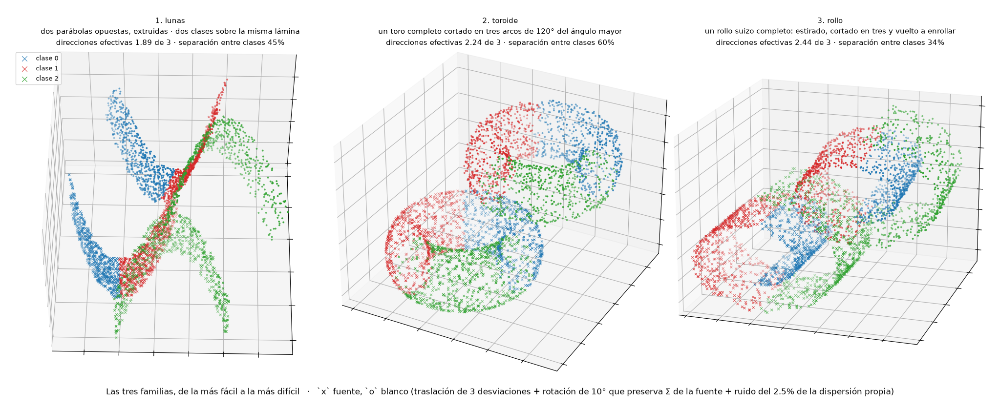

In [3]:
fig = plt.figure(figsize=(19.5, 8.0))
for i, (nom, fn) in enumerate(DURAS):
    Xs, ys, Xt, yt = construir_dura(fn)
    assert np.bincount(ys).max()/np.bincount(ys).min() < 1.15, (nom, np.bincount(ys))
    a = fig.add_subplot(1, 3, i+1, projection='3d'); a.set_box_aspect(None, zoom=1.18)
    for c in range(3):
        P = Xs[ys == c]
        a.scatter(P[:,0], P[:,1], P[:,2], c=COL_DURA[c], marker='x', s=11,
                  linewidths=.7, label=f'clase {c}' if i == 0 else None)
        Q = Xt[yt == c]
        a.scatter(Q[:,0], Q[:,1], Q[:,2], c=COL_DURA[c], marker='o', s=7,
                  alpha=1.0, edgecolors='none')
    todo = np.vstack([Xs, Xt]); pd_ = 0.05*(todo.max(0) - todo.min(0))
    a.set_xlim(todo[:,0].min()-pd_[0], todo[:,0].max()+pd_[0])
    a.set_ylim(todo[:,1].min()-pd_[1], todo[:,1].max()+pd_[1])
    a.set_zlim(todo[:,2].min()-pd_[2], todo[:,2].max()+pd_[2])
    a.view_init(*VISTA_DURA[nom])
    a.set_xticklabels([]); a.set_yticklabels([]); a.set_zticklabels([])
    a.set_title(f'{i+1}. {nom}' + chr(10) + NOTA_DURA[nom] + chr(10) +
                f'direcciones efectivas {dim_ef_dura(Xs):.2f} de 3 · '
                f'separación entre clases {entre_dura(Xs, ys):.0f}%',
                fontsize=10.5, linespacing=1.5)
    if i == 0: a.legend(loc='upper left', fontsize=9, markerscale=2.2)
# El pie sale de las BANDERAS y no escrito a mano. Decia 'rotación 30° sobre un
# eje genérico', que al cambiar la perturbación quedó mintiendo dos veces: ni es
# 30° ni es genérica. Una figura cuyo pie se escribe a mano vuelve a mentir en
# el próximo cambio.
fig.suptitle('Las tres familias, de la más fácil a la más difícil   ·   '
             '`x` fuente, `o` blanco (traslación de '
             f"{BANDERAS['TRASLADO_REL']:g} desviaciones + rotación de "
             f"{BANDERAS['ANGULO_SIGMA_GRADOS']:g}° que preserva Σ de la fuente "
             f"+ ruido del {BANDERAS['RUIDO_REL']:.1%} de la dispersión propia)",
             fontsize=11.5, y=0.055)
# top=0.99 recortaba los titulos de tres renglones.
fig.subplots_adjust(left=0.01, right=0.99, top=0.88, bottom=0.11, wspace=0.03)
_salida = FIGURAS/'familias_duras.png'
fig.savefig(_salida, dpi=105); plt.close(fig)
display(Image(filename=str(_salida)))

## Las tres arquitecturas

Las tres son **la misma red** salvo una capa, y esa capa está en el **mismo
lugar** en las tres — después de la primera oculta. Si cada una fuera a una capa
distinta, la comparación mediría el lugar y no el tipo.

La tabla de abajo la **imprime el propio modelo**, no está escrita a mano: una
tabla a mano decía seis capas en el cuaderno de una capa, donde el código
construye una sola oculta.

In [4]:
# La tabla sale de los modelos REALES, recorriendo sus modulos. Escrita a
# mano decia la red completa en el cuaderno de una capa --- el codigo construia
# una oculta y la tabla describia otra cosa --- y nadie lo nota mirando la tabla.
_red  = {q: MLP(FAMILIAS[0]['amb'], q) for q in NORMAS}
_mods = {q: list(_red[q].net) for q in NORMAS}
_n = max(len(v) for v in _mods.values())
def _desc(m):
    import torch.nn as _nn
    if isinstance(m, _nn.Linear):      return f"`Linear({m.in_features}, {m.out_features})`"
    if isinstance(m, _nn.BatchNorm1d): return f"**`BatchNorm1d({m.num_features})`**"
    if isinstance(m, _nn.LayerNorm):   return f"**`LayerNorm({m.normalized_shape[0]})`**"
    return f"`{type(m).__name__}`"
# Alineadas por ROL y no por posicion. La red sin normalizacion tiene un modulo
# MENOS, asi que indexar por posicion la corre un renglon entera: su Linear(32,32)
# aparecia en la fila 3 y el de las otras en la 4, como si fueran redes distintas.
# Se le inserta un hueco justo donde las otras llevan su capa de normalizacion.
import torch.nn as _tnn
# Donde cae la normalizacion lo DECIDE la red, no una constante: en la completa
# va despues de la primera oculta y en la de una capa va al final.
_pos_norm = min(k for q in NORMAS for k, m in enumerate(_mods[q])
                if isinstance(m, (_tnn.BatchNorm1d, _tnn.LayerNorm)))
_col = {}
for q in NORMAS:
    v = list(_mods[q])
    if not any(isinstance(m, (_tnn.BatchNorm1d, _tnn.LayerNorm)) for m in v):
        v.insert(_pos_norm, None)
    _col[q] = v
_n = max(len(v) for v in _col.values())
_fil = []
for k in range(_n):
    _fil.append([str(k+1)] + [(_desc(_col[q][k]) if k < len(_col[q]) and _col[q][k] is not None
                               else chr(8212)) for q in NORMAS])
_fil.append(['estado', 'ninguno', '`running_mean`, `running_var`', 'ninguno'])
_fil.append(['normaliza sobre', chr(8212), 'el **lote**, por canal',
             'los **features**, por muestra'])
_fil.append(['parámetros'] + [f"{sum(p.numel() for p in _red[q].parameters()):,}"
                              for q in NORMAS])
_enc = [''] + [NOMBRE_FILA[q] for q in NORMAS]
_md = ['| ' + ' | '.join(_enc) + ' |', '|' + '|'.join(['---']*len(_enc)) + '|']
_md += ['| ' + ' | '.join(r) + ' |' for r in _fil]
from IPython.display import Markdown as _Md, display as _dp
_dp(_Md(chr(10).join(_md)))
print(f"capas ocultas: {'UNA' if UNA_CAPA else 'DOS'}  ·  "
      f"modulos por red: {[len(_mods[q]) for q in NORMAS]}")

|  | sin normalización | BatchNorm | LayerNorm |
|---|---|---|---|
| 1 | `Linear(3, 16)` | `Linear(3, 16)` | `Linear(3, 16)` |
| 2 | `ReLU` | `ReLU` | `ReLU` |
| 3 | — | **`BatchNorm1d(16)`** | **`LayerNorm(16)`** |
| estado | ninguno | `running_mean`, `running_var` | ninguno |
| normaliza sobre | — | el **lote**, por canal | los **features**, por muestra |
| parámetros | 64 | 96 | 96 |

capas ocultas: UNA  ·  modulos por red: [2, 3, 3]


Ese lugar salió de medir BatchNorm sobre 5 semillas: sólo en la primera
capa lleva toroides de 0,3651 a 0,7222 y lunas de 0,3306 a 0,6534, por encima de
ponerlo en las dos ocultas; en la salida es el **peor** sitio (0,4590 en rollo,
debajo de no poner ninguno).

**sin normalizacion.** Sin normalización en ninguna capa. Es el brazo que la hipótesis necesita que funcione: constreñir el latente con el regularizador de Rényi solo, sin depender de normalizar por lote.

**BatchNorm.** BatchNorm después de la primera oculta. Resta la media por canal sobre el LOTE, así que lo que le hace a una muestra depende de con quién le tocó viajar, y en el paso 3 reestima sus corridas con lotes del dominio nuevo.

**LayerNorm.** LayerNorm en el mismo lugar. Normaliza por FEATURES dentro de cada muestra: no tiene estado y no mira el lote, así que no puede traer lo que BatchNorm trae por reestimar. Es la comparación que separa «normalizar ayuda» de «reestimar ayuda».

**Y por eso la tercera fila existe.** LayerNorm normaliza sin tener estado que
reestimar, así que es la comparación que separa «normalizar ayuda» de
«reestimar ayuda» — que es lo que AdaBN hace y lo que la tabla de cada dataset
mide aparte.

## La figura, una por dataset

Cada dataset lleva **un cuadro animado de 3 filas × 4 columnas**, con la fuente y
la cabeza quietas en la fase 2.

| | col 1 | col 2 | col 3 | col 4 |
|---|---|---|---|---|
| **fila 1** sin normalización | embedding, color = clase **real** | el mismo, color = **predicción** | loss de la fase 1 | loss de la fase 2 |
| **fila 2** BatchNorm | ídem | ídem | ídem | ídem |
| **fila 3** LayerNorm | ídem | ídem | ídem | ídem |

**Las filas son las tres normalizaciones.** `K_mix` va balanceado por **traza**
(r28, Ec. 32): cada bloque diagonal dividido por su propia traza y el cruzado
por la media geometrica de las dos, de modo que cada dominio aporta la mitad
de la masa. La version por cardinalidad tiraba el sopesado de confianza: con
`w` medio 0.5 la fuente se quedaba con el 80% de la mezcla.

Eran **dos** figuras por dataset: el régimen de la fuente era el segundo eje.
Se retiró. Medido sobre 45 pares **apareados** —las dos filas compartían
semilla, datos y los pesos de la fase 1 bit a bit— soltar la fuente mueve
`+0.0026` con IC 95% `[−0.0106, +0.0157]`: cualquier efecto está acotado a ±1,6
puntos de acierto.

Y la razón para quedarse con la quieta no es el empate: **con la fuente quieta el
término de Rényi es el único con camino de gradiente**, así que el número del
blanco es atribuible a él y a nada más. Con la fuente suelta la CE también mueve
el encoder compartido y el número es una mezcla que no se puede repartir.

## lunas

In [5]:
G0 = animar(FAMILIAS[0], POR, DAT, FIGURAS)

      paso_lunas_quieta.gif  4.2 MB


### lunas — la figura

`f_s` entra desprendida y ni el encoder ni la cabeza están en el optimizador, así
que la CE se calcula y no mueve nada: **el único término con camino de gradiente
es el de Rényi**. Lo que se ve moverse es el encoder del blanco, y nada más.

Arriba el embedding paso a paso: a la izquierda por clase real, a la derecha por
lo que predice la cabeza. Abajo, la pérdida: a la izquierda la CE de la fase 1, a
la derecha el Rényi de la fase 2 —que es el loss entero de esta figura.

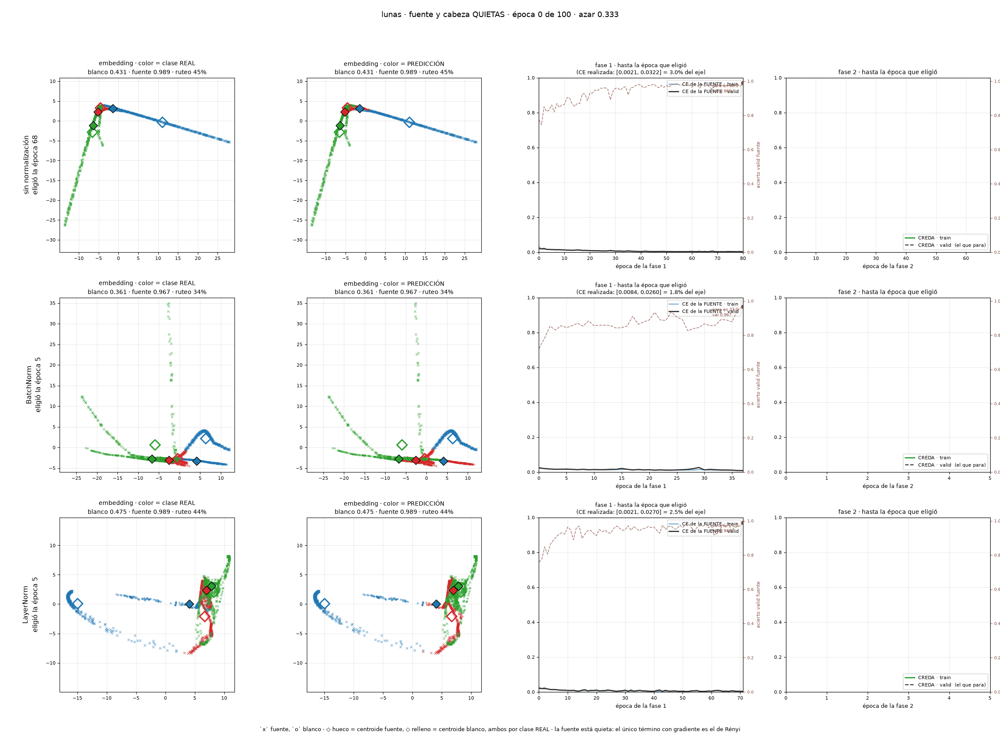

In [6]:
display(Image(filename=str(G0['quieta'])))

### lunas — la tabla

Las filas van en **escalera de intervención**, de menos a más, y es el orden en
que hay que leerlas:

1. **`.predict`** — el modelo de la fuente aplicado al blanco, sin tocar nada.
   Es el piso: lo que se obtiene por no hacer nada. Una fila por arquitectura,
   porque cada una entrena su propia fuente.
2. **AdaBN** — sólo las corridas de BatchNorm, reestimadas con lotes del blanco.
   Sin optimizador y sin gradiente. Sólo existe con BatchNorm.
3. **CREDA** — el regularizador de Rényi moviendo el encoder del blanco.

`.predict` sale del **punto de control del paso 0** de la misma corrida, no de un
barrido aparte: ahí el encoder del blanco es un `deepcopy` del de la fuente,
medido en `eval()`. Eso lo hace **apareado** con el brazo de CREDA que va debajo
—comparten la fase 1 bit a bit— así que la diferencia entre los dos no lleva
adentro la variación de entrenar otra fuente.

Las filas sin trayectoria llevan `—` en pico y paso del pico: repetir ahí su
valor final lo haría comparable con un máximo que nunca midieron.

In [7]:
tabla_dataset(FAMILIAS[0]['nombre'], CELDAS, ADA, SEMILLAS)

**lunas · 10 semillas · media ± desvío · azar 0.3333 · test, sólo reporte**

| método | normalización | época fuente | época que eligió | fuente · test | blanco · test | vigía: fuente conservada | blanco pico · test (oráculo) |
|---|---|---|---|---|---|---|---|
| `.predict` (sin adaptar) | sin normalización | 52 | — | 0.9850 ± 0.0067 | 0.5117 ± 0.0498 | — | — |
| `.predict` (sin adaptar) | BatchNorm | 58 | — | 0.9725 ± 0.0106 | 0.3500 ± 0.0625 | — | — |
| `.predict` (sin adaptar) | LayerNorm | 33 | — | 0.9806 ± 0.0067 | 0.5017 ± 0.1073 | — | — |
| **AdaBN** (sólo buffers, sin optimizador) | BatchNorm | — | — | 0.9725 ± 0.0106 | 0.4883 ± 0.0664 | — | — |
| **CREDA** · HP sintonizados | sin normalización | 52 | 32 | 0.9850 ± 0.0067 | 0.7222 ± 0.0560 | 0.7406 ± 0.0295 | 0.7131 ± 0.0402 |
| **CREDA** · HP sintonizados | BatchNorm | 58 | 5 | 0.9725 ± 0.0106 | 0.4761 ± 0.0530 | 0.6381 ± 0.0471 | 0.5086 ± 0.0992 |
| **CREDA** · HP sintonizados | LayerNorm | 33 | 34 | 0.9806 ± 0.0067 | 0.7086 ± 0.1003 | 0.6975 ± 0.0393 | 0.7158 ± 0.0910 |

### lunas — los tests declarados


In [8]:
display(tabla_sin_contra_con(FAMILIAS[0]['nombre'], CELDAS, BANDERAS))
display(tabla_tres_brazos(FAMILIAS[0]['nombre'], CELDAS, ADA, BANDERAS))


**lunas · 10 semillas · test, sólo reporte · balanceado por traza (Ec. 32)**

| normalización | con CREDA | sin CREDA | Δ = con − sin | IC95 de Δ | t(9) | p | Shapiro p | Wilcoxon p | gana |
|---|---|---|---|---|---|---|---|---|---|
| sin normalización | 0.7222 | 0.5117 | +0.2106 | [+0.1677, +0.2534] | 11.13 | 0.00000 | 0.345 | 0.0020 | 10/10 |
| BatchNorm | 0.4761 | 0.3500 | +0.1261 | [+0.0925, +0.1598] | 8.48 | 0.00001 | 0.389 | 0.0020 | 10/10 |
| LayerNorm | 0.7086 | 0.5017 | +0.2069 | [+0.1458, +0.2681] | 7.66 | 0.00003 | 0.056 | 0.0020 | 10/10 |
| PROMEDIO | 0.6356 | 0.4544 | +0.1812 | [+0.1503, +0.2121] | 13.26 | 0.00000 | 0.869 | 0.0020 | 10/10 |

`Δ = con CREDA − sin CREDA`, así que **Δ>0 quiere decir que gana `con CREDA`** · `PROMEDIO` promedia la normalización, DENTRO de cada semilla, o sea 10 pares, y no agrupa los 30 de celda-semilla: la semilla 0 está en las tres normalizaciones · t pareado, Shapiro-Wilk sobre las diferencias pareadas, Wilcoxon al lado

**LUNAS · BatchNorm · 10 semillas · test, sólo reporte**

Friedman χ²(2) = 15.20 · p = 0.00050 · 10 bloques de semilla · rangos medios (3 = mejor): `.predict` 1.00 | `AdaBN` 2.60 | `CREDA` 2.40

| gana si Δ>0 | contra | Δ = 1ª − 2ª | IC95 de Δ | p (Wilcoxon) | p Holm (familia de 3) | gana |
|---|---|---|---|---|---|---|
| AdaBN | .predict | +0.1383 | [+0.0943, +0.1824] | 0.0020 | 0.0059 | 10/10 |
| CREDA | .predict | +0.1261 | [+0.0925, +0.1598] | 0.0020 | 0.0059 | 10/10 |
| CREDA | AdaBN | -0.0122 | [-0.0615, +0.0370] | 0.5703 | 0.5703 | 4/10 |

`Δ = (columna «gana si Δ>0») − (columna «contra»)`, así que **Δ>0 quiere decir que gana el PRIMERO de los dos nombrados** · el orden del par es fijo y no sigue al ganador · Holm dentro de los 3 pares de este toyset, no sobre los 9

## toroide

In [9]:
G1 = animar(FAMILIAS[1], POR, DAT, FIGURAS)

      paso_toroide_quieta.gif  6.8 MB


### toroide — la figura

`f_s` entra desprendida y ni el encoder ni la cabeza están en el optimizador, así
que la CE se calcula y no mueve nada: **el único término con camino de gradiente
es el de Rényi**. Lo que se ve moverse es el encoder del blanco, y nada más.

Arriba el embedding paso a paso: a la izquierda por clase real, a la derecha por
lo que predice la cabeza. Abajo, la pérdida: a la izquierda la CE de la fase 1, a
la derecha el Rényi de la fase 2 —que es el loss entero de esta figura.

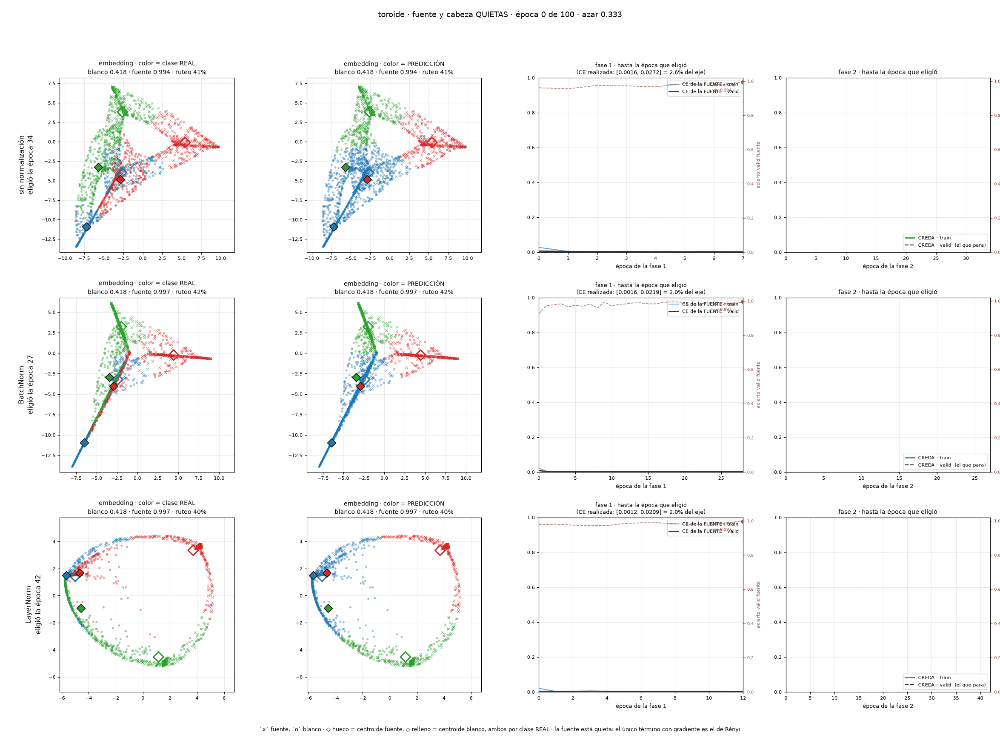

In [10]:
display(Image(filename=str(G1['quieta'])))

### toroide — la tabla

Las filas van en **escalera de intervención**, de menos a más, y es el orden en
que hay que leerlas:

1. **`.predict`** — el modelo de la fuente aplicado al blanco, sin tocar nada.
   Es el piso: lo que se obtiene por no hacer nada. Una fila por arquitectura,
   porque cada una entrena su propia fuente.
2. **AdaBN** — sólo las corridas de BatchNorm, reestimadas con lotes del blanco.
   Sin optimizador y sin gradiente. Sólo existe con BatchNorm.
3. **CREDA** — el regularizador de Rényi moviendo el encoder del blanco.

`.predict` sale del **punto de control del paso 0** de la misma corrida, no de un
barrido aparte: ahí el encoder del blanco es un `deepcopy` del de la fuente,
medido en `eval()`. Eso lo hace **apareado** con el brazo de CREDA que va debajo
—comparten la fase 1 bit a bit— así que la diferencia entre los dos no lleva
adentro la variación de entrenar otra fuente.

Las filas sin trayectoria llevan `—` en pico y paso del pico: repetir ahí su
valor final lo haría comparable con un máximo que nunca midieron.

In [11]:
tabla_dataset(FAMILIAS[1]['nombre'], CELDAS, ADA, SEMILLAS)

**toroide · 10 semillas · media ± desvío · azar 0.3333 · test, sólo reporte**

| método | normalización | época fuente | época que eligió | fuente · test | blanco · test | vigía: fuente conservada | blanco pico · test (oráculo) |
|---|---|---|---|---|---|---|---|
| `.predict` (sin adaptar) | sin normalización | 15 | — | 0.9881 ± 0.0076 | 0.4204 ± 0.0138 | — | — |
| `.predict` (sin adaptar) | BatchNorm | 22 | — | 0.9903 ± 0.0060 | 0.4157 ± 0.0159 | — | — |
| `.predict` (sin adaptar) | LayerNorm | 20 | — | 0.9890 ± 0.0078 | 0.4215 ± 0.0211 | — | — |
| **AdaBN** (sólo buffers, sin optimizador) | BatchNorm | — | — | 0.9903 ± 0.0060 | 0.7578 ± 0.0440 | — | — |
| **CREDA** · HP sintonizados | sin normalización | 15 | 29 | 0.9881 ± 0.0076 | 0.8772 ± 0.0376 | 0.8312 ± 0.0364 | 0.8949 ± 0.0135 |
| **CREDA** · HP sintonizados | BatchNorm | 22 | 36 | 0.9903 ± 0.0060 | 0.8479 ± 0.0415 | 0.7721 ± 0.0423 | 0.8764 ± 0.0269 |
| **CREDA** · HP sintonizados | LayerNorm | 20 | 23 | 0.9890 ± 0.0078 | 0.8631 ± 0.0321 | 0.8011 ± 0.0310 | 0.8844 ± 0.0212 |

### toroide — los tests declarados


In [12]:
display(tabla_sin_contra_con(FAMILIAS[1]['nombre'], CELDAS, BANDERAS))
display(tabla_tres_brazos(FAMILIAS[1]['nombre'], CELDAS, ADA, BANDERAS))


**toroide · 10 semillas · test, sólo reporte · balanceado por traza (Ec. 32)**

| normalización | con CREDA | sin CREDA | Δ = con − sin | IC95 de Δ | t(9) | p | Shapiro p | Wilcoxon p | gana |
|---|---|---|---|---|---|---|---|---|---|
| sin normalización | 0.8772 | 0.4204 | +0.4568 | [+0.4221, +0.4916] | 29.72 | 0.00000 | 0.005 | 0.0020 | 10/10 |
| BatchNorm | 0.8479 | 0.4157 | +0.4323 | [+0.3928, +0.4717] | 24.80 | 0.00000 | 0.250 | 0.0020 | 10/10 |
| LayerNorm | 0.8631 | 0.4215 | +0.4417 | [+0.4163, +0.4670] | 39.45 | 0.00000 | 0.994 | 0.0020 | 10/10 |
| PROMEDIO | 0.8628 | 0.4192 | +0.4436 | [+0.4165, +0.4707] | 37.08 | 0.00000 | 0.940 | 0.0020 | 10/10 |

`Δ = con CREDA − sin CREDA`, así que **Δ>0 quiere decir que gana `con CREDA`** · `PROMEDIO` promedia la normalización, DENTRO de cada semilla, o sea 10 pares, y no agrupa los 30 de celda-semilla: la semilla 0 está en las tres normalizaciones · t pareado, Shapiro-Wilk sobre las diferencias pareadas, Wilcoxon al lado

**TOROIDE · BatchNorm · 10 semillas · test, sólo reporte**

Friedman χ²(2) = 18.20 · p = 0.00011 · 10 bloques de semilla · rangos medios (3 = mejor): `.predict` 1.00 | `AdaBN` 2.10 | `CREDA` 2.90

| gana si Δ>0 | contra | Δ = 1ª − 2ª | IC95 de Δ | p (Wilcoxon) | p Holm (familia de 3) | gana |
|---|---|---|---|---|---|---|
| AdaBN | .predict | +0.3421 | [+0.3109, +0.3733] | 0.0020 | 0.0059 | 10/10 |
| CREDA | .predict | +0.4323 | [+0.3928, +0.4717] | 0.0020 | 0.0059 | 10/10 |
| CREDA | AdaBN | +0.0902 | [+0.0414, +0.1389] | 0.0039 | 0.0059 | 9/10 |

`Δ = (columna «gana si Δ>0») − (columna «contra»)`, así que **Δ>0 quiere decir que gana el PRIMERO de los dos nombrados** · el orden del par es fijo y no sigue al ganador · Holm dentro de los 3 pares de este toyset, no sobre los 9

## rollo

In [13]:
G2 = animar(FAMILIAS[2], POR, DAT, FIGURAS)

      paso_rollo_quieta.gif  5.8 MB


### rollo — la figura

`f_s` entra desprendida y ni el encoder ni la cabeza están en el optimizador, así
que la CE se calcula y no mueve nada: **el único término con camino de gradiente
es el de Rényi**. Lo que se ve moverse es el encoder del blanco, y nada más.

Arriba el embedding paso a paso: a la izquierda por clase real, a la derecha por
lo que predice la cabeza. Abajo, la pérdida: a la izquierda la CE de la fase 1, a
la derecha el Rényi de la fase 2 —que es el loss entero de esta figura.

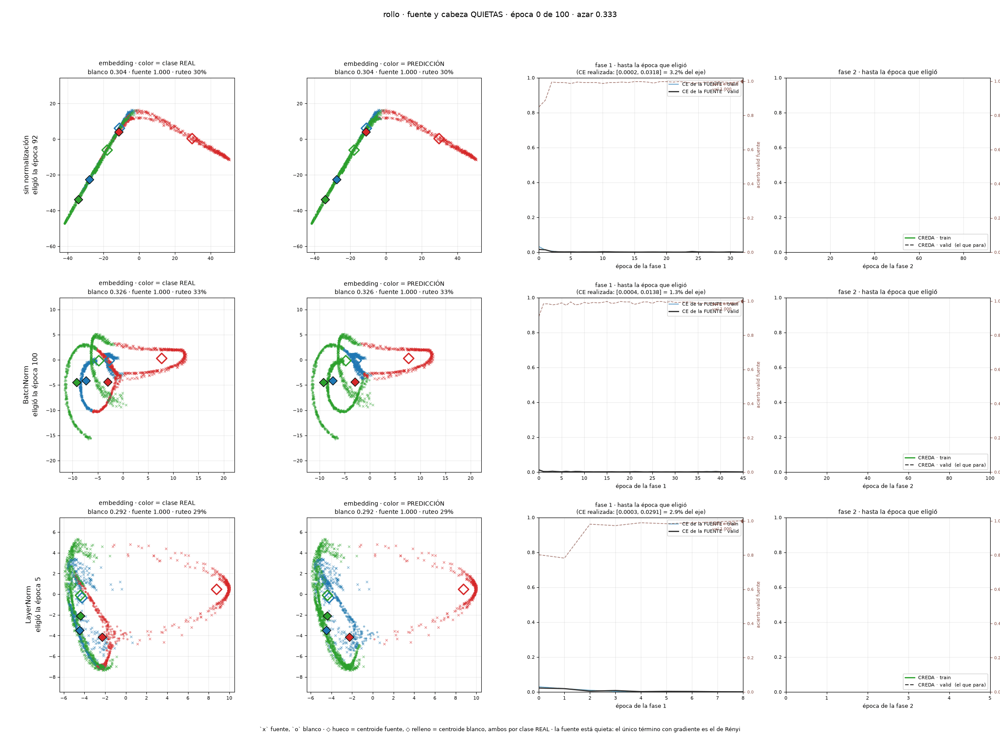

In [14]:
display(Image(filename=str(G2['quieta'])))

### rollo — la tabla

Las filas van en **escalera de intervención**, de menos a más, y es el orden en
que hay que leerlas:

1. **`.predict`** — el modelo de la fuente aplicado al blanco, sin tocar nada.
   Es el piso: lo que se obtiene por no hacer nada. Una fila por arquitectura,
   porque cada una entrena su propia fuente.
2. **AdaBN** — sólo las corridas de BatchNorm, reestimadas con lotes del blanco.
   Sin optimizador y sin gradiente. Sólo existe con BatchNorm.
3. **CREDA** — el regularizador de Rényi moviendo el encoder del blanco.

`.predict` sale del **punto de control del paso 0** de la misma corrida, no de un
barrido aparte: ahí el encoder del blanco es un `deepcopy` del de la fuente,
medido en `eval()`. Eso lo hace **apareado** con el brazo de CREDA que va debajo
—comparten la fase 1 bit a bit— así que la diferencia entre los dos no lleva
adentro la variación de entrenar otra fuente.

Las filas sin trayectoria llevan `—` en pico y paso del pico: repetir ahí su
valor final lo haría comparable con un máximo que nunca midieron.

In [15]:
tabla_dataset(FAMILIAS[2]['nombre'], CELDAS, ADA, SEMILLAS)

**rollo · 10 semillas · media ± desvío · azar 0.3333 · test, sólo reporte**

| método | normalización | época fuente | época que eligió | fuente · test | blanco · test | vigía: fuente conservada | blanco pico · test (oráculo) |
|---|---|---|---|---|---|---|---|
| `.predict` (sin adaptar) | sin normalización | 5 | — | 0.9956 ± 0.0028 | 0.3318 ± 0.0134 | — | — |
| `.predict` (sin adaptar) | BatchNorm | 18 | — | 0.9950 ± 0.0030 | 0.3528 ± 0.0183 | — | — |
| `.predict` (sin adaptar) | LayerNorm | 8 | — | 0.9959 ± 0.0043 | 0.3519 ± 0.0295 | — | — |
| **AdaBN** (sólo buffers, sin optimizador) | BatchNorm | — | — | 0.9950 ± 0.0030 | 0.6955 ± 0.0592 | — | — |
| **CREDA** · HP sintonizados | sin normalización | 5 | 27 | 0.9956 ± 0.0028 | 0.8916 ± 0.0276 | 0.7482 ± 0.0350 | 0.8963 ± 0.0239 |
| **CREDA** · HP sintonizados | BatchNorm | 18 | 93 | 0.9950 ± 0.0030 | 0.7959 ± 0.0886 | 0.6301 ± 0.0630 | 0.7810 ± 0.0803 |
| **CREDA** · HP sintonizados | LayerNorm | 8 | 23 | 0.9959 ± 0.0043 | 0.6089 ± 0.1667 | 0.7945 ± 0.1012 | 0.6166 ± 0.1808 |

### rollo — los tests declarados


In [16]:
display(tabla_sin_contra_con(FAMILIAS[2]['nombre'], CELDAS, BANDERAS))
display(tabla_tres_brazos(FAMILIAS[2]['nombre'], CELDAS, ADA, BANDERAS))


**rollo · 10 semillas · test, sólo reporte · balanceado por traza (Ec. 32)**

| normalización | con CREDA | sin CREDA | Δ = con − sin | IC95 de Δ | t(9) | p | Shapiro p | Wilcoxon p | gana |
|---|---|---|---|---|---|---|---|---|---|
| sin normalización | 0.8916 | 0.3318 | +0.5598 | [+0.5405, +0.5790] | 65.76 | 0.00000 | 0.779 | 0.0020 | 10/10 |
| BatchNorm | 0.7959 | 0.3528 | +0.4431 | [+0.3749, +0.5114] | 14.69 | 0.00000 | 0.020 | 0.0020 | 10/10 |
| LayerNorm | 0.6089 | 0.3519 | +0.2570 | [+0.1424, +0.3716] | 5.07 | 0.00067 | 0.547 | 0.0020 | 10/10 |
| PROMEDIO | 0.7654 | 0.3455 | +0.4200 | [+0.3737, +0.4663] | 20.52 | 0.00000 | 0.974 | 0.0020 | 10/10 |

`Δ = con CREDA − sin CREDA`, así que **Δ>0 quiere decir que gana `con CREDA`** · `PROMEDIO` promedia la normalización, DENTRO de cada semilla, o sea 10 pares, y no agrupa los 30 de celda-semilla: la semilla 0 está en las tres normalizaciones · t pareado, Shapiro-Wilk sobre las diferencias pareadas, Wilcoxon al lado

**ROLLO · BatchNorm · 10 semillas · test, sólo reporte**

Friedman χ²(2) = 18.20 · p = 0.00011 · 10 bloques de semilla · rangos medios (3 = mejor): `.predict` 1.00 | `AdaBN` 2.10 | `CREDA` 2.90

| gana si Δ>0 | contra | Δ = 1ª − 2ª | IC95 de Δ | p (Wilcoxon) | p Holm (familia de 3) | gana |
|---|---|---|---|---|---|---|
| AdaBN | .predict | +0.3428 | [+0.3020, +0.3835] | 0.0020 | 0.0059 | 10/10 |
| CREDA | .predict | +0.4431 | [+0.3749, +0.5114] | 0.0020 | 0.0059 | 10/10 |
| CREDA | AdaBN | +0.1003 | [+0.0584, +0.1423] | 0.0039 | 0.0059 | 9/10 |

`Δ = (columna «gana si Δ>0») − (columna «contra»)`, así que **Δ>0 quiere decir que gana el PRIMERO de los dos nombrados** · el orden del par es fijo y no sigue al ganador · Holm dentro de los 3 pares de este toyset, no sobre los 9

In [17]:
# El rotulo de esta seccion sale del DATO y no de una frase escrita a mano.
# Decia 'sobre cinco semillas' encima de numeros de diez --- el mismo defecto
# que `_semillas` existe para cerrar, y que ya habia enviado una tabla rotulada
# con un conteo que nadie midio. Una celda de markdown no puede contar nada,
# asi que esto es una celda de CODIGO que emite el markdown.
_n = _semillas((len(v) for v in CELDAS.values()), BANDERAS,
               'el texto del paso 4')
_fams = len({k[0] for k in CELDAS})
_norms = len(BANDERAS['POS_FILAS'])
display(Markdown(
    '## El paso 4, leído por dentro' + chr(10)*2
    + f'La tabla de arriba ya corrió el barrido: {_fams} familias × {_norms} '
      f'normalizaciones, sobre {_n} semillas. Lo que sigue **lee ese mismo '
      '`CELDAS`**, no vuelve a correrlo.' + chr(10)*2
    + 'Esto importa más de lo que parece. Cuando esta celda tenía su propio '
      'barrido, calculaba exactamente los mismos números una segunda vez '
      '— y dos barridos independientes pueden divergir sin que nadie lo note.'))

## El paso 4, leído por dentro

La tabla de arriba ya corrió el barrido: 3 familias × 3 normalizaciones, sobre 10 semillas. Lo que sigue **lee ese mismo `CELDAS`**, no vuelve a correrlo.

Esto importa más de lo que parece. Cuando esta celda tenía su propio barrido, calculaba exactamente los mismos números una segunda vez — y dos barridos independientes pueden divergir sin que nadie lo note.

## El sopesado bajo contaminación

Todo el sopesado se resume acá, en tres gifs: **qué hace el peso de la Ec. 19**,
construido y no medido.

Tres puntos arrancan en una frontera de decisión del cabezal de la FUENTE y
caminan al centro de una clase. `w = 1 − Ĥ₂(g)/ln C` es función del posterior y
nada más, así que esto **no es una medición con varianza**: es una propiedad de
la ecuación y del cabezal, exacta.

Los tres arrancan en lugares **distintos** a propósito. Medido sobre el cabezal
real: una frontera de **dos** clases da `w = 0.369`, la frontera **triple** da
`w = 0.000003`, y el centro de clase da `w = 1.000001`. Tres puntos en fronteras
dobles arrancarían los tres en 0.369 y las tres curvas serían la misma; el
triple es el único lugar donde `w` se anula de verdad.

Ahí se ve la premisa literal: desde el empate a tres el punto puede irse a
**cualquiera** de las tres clases y `w` sube igual — **nadie le preguntó su
etiqueta**. Eso es lo que esto demuestra y lo único que demuestra: que `w` mide
**confianza**, no acierto.


In [18]:
# El registro de contaminación, que es de donde salen las dos tablas de
# esta sección. Lo dejó `barrer_contaminacion` en el cuaderno generador;
# acá no se vuelve a entrenar nada, igual que el resto del cuaderno.
CONTAM = cargar_contaminacion(ENTRADA)

# El escenario que las tablas reportan: el ÚNICO que esta sección corre, leído
# de `ESCALERA_CONTAMINACION` y no escrito acá. Decisión del operador del
# 2026-10-19: un solo nivel de ruido y sin la base limpia, porque "sin la base
# limpia, eso ya es la sección 1".
#
# Lo que decía antes, y por qué no se sostenía --- se deja escrito porque el
# argumento suena bien y alguien lo va a volver a hacer:
#
#   "El escenario que las tablas reportan, y por qué es el limpio: el eje de
#    esta sección es la BANDERA del sopesado, y `rho = 0` es el único nivel
#    donde los dos brazos difieren sólo en ella. Con contaminación encima, una
#    diferencia es del peso o del daño y la tabla no puede decir cuál."
#
# Los dos brazos corren sobre LOS MISMOS datos dañados, con la misma fase 1
# congelada y los mismos HP2; la única diferencia entre ellos es la bandera.
# El daño es una CONDICIÓN fijada, no un confundidor dentro del par, y el
# Wilcoxon de esta tabla es pareado POR SEMILLA DENTRO DEL NIVEL. El
# confundidor que ese párrafo describe aparecería comparando un brazo en rho=0
# contra el otro en rho=0.30, que es una comparación que esta tabla no hace.
#
# Y es la pregunta que el plan declaró: `odd/tasks/toyset-tests-estadisticos-y-
# ruido.md` predice "w on should beat w off, and the gap should grow with rho",
# que sólo se puede leer donde hay daño.
RHO_REPORTADO = float(ESCALERA_CONTAMINACION[0])
assert RHO_REPORTADO > 0.0, (
    RHO_REPORTADO, 'el nivel que se reporta volvió a ser el limpio: eso es la '
    'sección 1 y acá sería la misma celda dos veces')
assert len(ESCALERA_CONTAMINACION) == 1, (
    ESCALERA_CONTAMINACION, 'la sección corre más de un nivel y estas tablas '
    'reportan uno: hay que recorrerlos o decir cuál se eligió')
print('escenarios en el registro:', sorted(CONTAM['celdas']))


escenarios en el registro: [('lunas', 'frontera', 0.3), ('lunas', 'reubicado', 0.3), ('rollo', 'frontera', 0.3), ('rollo', 'reubicado', 0.3), ('toroide', 'frontera', 0.3), ('toroide', 'reubicado', 0.3)]


### lunas — qué hace el peso, por construcción

Tres puntos que arrancan en una frontera de decisión del cabezal de la FUENTE y
caminan al centro de una clase. **No es una medición**: `w = 1 − Ĥ₂(g)/ln C` es
función del posterior y nada más, así que la curva es una propiedad de la
Ec. 19 y del cabezal, exacta y sin varianza.

Los tres arrancan en lugares **distintos** a propósito. Medido sobre el cabezal
real: una frontera de **dos** clases da `w = 0.369`, la frontera **triple** da
`w = 0.000003`, y el centro de clase da `w = 1.000001`. Tres puntos en
fronteras dobles arrancarían los tres en 0.369 y las tres curvas serían la
misma; el triple es el único lugar donde `w` se anula de verdad.

Y ahí se ve la premisa literal: desde el empate a tres el punto puede irse a
**cualquiera** de las tres clases y `w` sube igual — **nadie le preguntó su
etiqueta**. Eso es lo que la figura demuestra y lo único que demuestra: que `w`
mide **confianza**, no acierto.

      fronteras_w_lunas.gif  0.9 MB
CREDA/Results/tesis/figuras/fronteras_w_lunas.gif


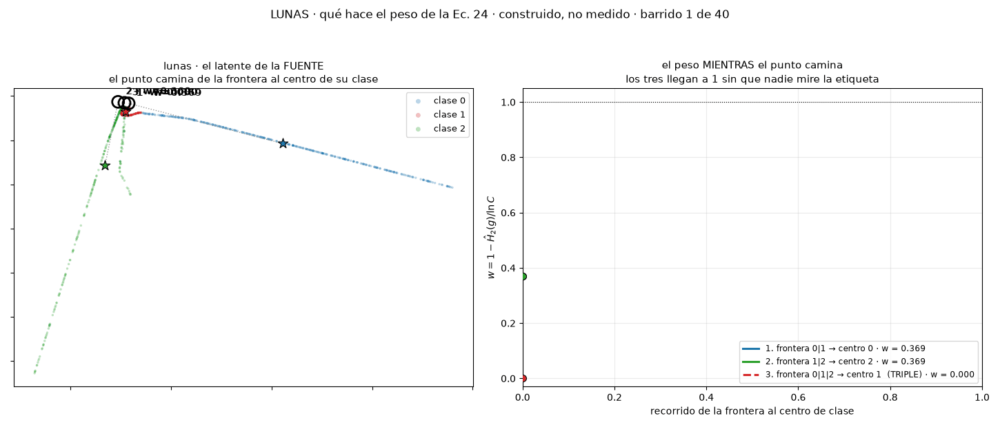

In [19]:
_f = FAMILIAS[0]
_D = datos_semilla(_f, 0)
_enc, _cab, _, _ = fase1_congelada(_f, _D, 'ninguna', 0, HP1['lunas'])
_enc.eval()
with torch.no_grad():
    _H = _enc(_D['Xs_tr']).numpy()
_r = animar_fronteras_w('lunas', _H, _D['ys_tr'].numpy(), _cab,
                        FIGURAS, pasos=40)
print(_r.relative_to(ROOT))
display(Image(filename=str(_r)))


### lunas — la tabla


In [20]:
display(tabla_sopesado_acc(FAMILIAS[0]['nombre'], CONTAM,
                           MODO_REUBICADO, RHO_REPORTADO))


**lunas · 10 semillas · batchnorm (la exige AdaBN, no la elige una comparación) · reubicado · ρ = 0.30 · media ± desvío · azar 0.3333**

| método | época que eligió | acc fuente (test) | acc blanco (test) | vigía final |
|---|---|---|---|---|
| **.predict** | — | — | 0.3500 ± 0.0625 | — |
| **AdaBN** | — | — | 0.4814 ± 0.0585 | — |
| **CREDA sin sopesado** | 54 | 0.9725 ± 0.0106 | 0.5639 ± 0.0934 | 0.6508 ± 0.0687 |
| **CREDA con sopesado** | 26 | 0.9725 ± 0.0106 | 0.4686 ± 0.0790 | 0.6211 ± 0.0583 |

### lunas — los tests declarados


In [21]:
display(tabla_sopesado_test(FAMILIAS[0]['nombre'], CONTAM,
                            MODO_REUBICADO, RHO_REPORTADO))


**lunas · 10 semillas · batchnorm · reubicado · ρ = 0.30 · test, sólo reporte**

| par | con | sin | Δ | IC95 de Δ | t(9) | p | Shapiro p | Wilcoxon p | gana |
|---|---|---|---|---|---|---|---|---|---|
| con sopesado − sin sopesado | 0.4686 | 0.5639 | -0.0953 | [-0.1635, -0.0271] | -3.159 | 0.0116 | 0.3190 | 0.0195 | 2/10 |

`Δ = con sopesado − sin sopesado`, así que **Δ>0 quiere decir que gana el sopesado** · los dos brazos difieren SOLO en la bandera del peso · t pareado, Shapiro-Wilk sobre las diferencias pareadas, Wilcoxon al lado

### toroide — qué hace el peso, por construcción

Tres puntos que arrancan en una frontera de decisión del cabezal de la FUENTE y
caminan al centro de una clase. **No es una medición**: `w = 1 − Ĥ₂(g)/ln C` es
función del posterior y nada más, así que la curva es una propiedad de la
Ec. 19 y del cabezal, exacta y sin varianza.

Los tres arrancan en lugares **distintos** a propósito. Medido sobre el cabezal
real: una frontera de **dos** clases da `w = 0.369`, la frontera **triple** da
`w = 0.000003`, y el centro de clase da `w = 1.000001`. Tres puntos en
fronteras dobles arrancarían los tres en 0.369 y las tres curvas serían la
misma; el triple es el único lugar donde `w` se anula de verdad.

Y ahí se ve la premisa literal: desde el empate a tres el punto puede irse a
**cualquiera** de las tres clases y `w` sube igual — **nadie le preguntó su
etiqueta**. Eso es lo que la figura demuestra y lo único que demuestra: que `w`
mide **confianza**, no acierto.

      fronteras_w_toroide.gif  1.1 MB
CREDA/Results/tesis/figuras/fronteras_w_toroide.gif


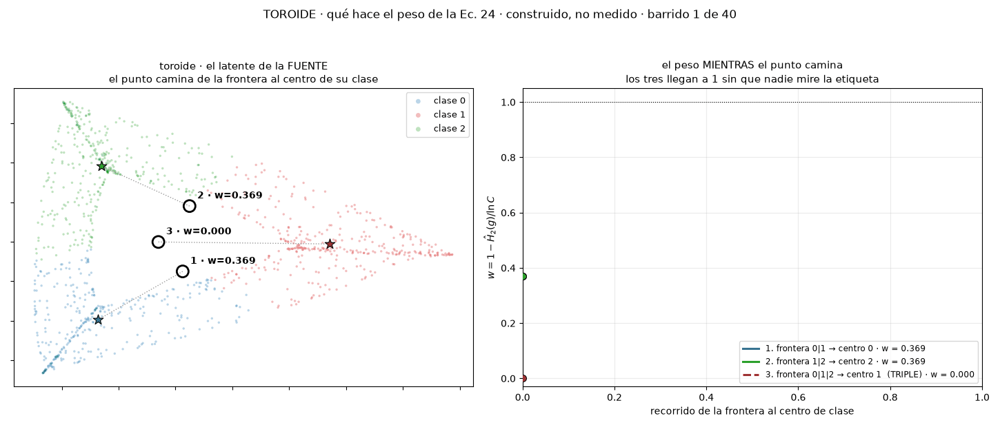

In [22]:
_f = FAMILIAS[1]
_D = datos_semilla(_f, 0)
_enc, _cab, _, _ = fase1_congelada(_f, _D, 'ninguna', 0, HP1['toroide'])
_enc.eval()
with torch.no_grad():
    _H = _enc(_D['Xs_tr']).numpy()
_r = animar_fronteras_w('toroide', _H, _D['ys_tr'].numpy(), _cab,
                        FIGURAS, pasos=40)
print(_r.relative_to(ROOT))
display(Image(filename=str(_r)))


### toroide — la tabla


In [23]:
display(tabla_sopesado_acc(FAMILIAS[1]['nombre'], CONTAM,
                           MODO_REUBICADO, RHO_REPORTADO))


**toroide · 10 semillas · batchnorm (la exige AdaBN, no la elige una comparación) · reubicado · ρ = 0.30 · media ± desvío · azar 0.3333**

| método | época que eligió | acc fuente (test) | acc blanco (test) | vigía final |
|---|---|---|---|---|
| **.predict** | — | — | 0.4157 ± 0.0159 | — |
| **AdaBN** | — | — | 0.7517 ± 0.0466 | — |
| **CREDA sin sopesado** | 46 | 0.9903 ± 0.0060 | 0.8877 ± 0.0405 | 0.7944 ± 0.0418 |
| **CREDA con sopesado** | 57 | 0.9903 ± 0.0060 | 0.8924 ± 0.0298 | 0.8000 ± 0.0353 |

### toroide — los tests declarados


In [24]:
display(tabla_sopesado_test(FAMILIAS[1]['nombre'], CONTAM,
                            MODO_REUBICADO, RHO_REPORTADO))


**toroide · 10 semillas · batchnorm · reubicado · ρ = 0.30 · test, sólo reporte**

| par | con | sin | Δ | IC95 de Δ | t(9) | p | Shapiro p | Wilcoxon p | gana |
|---|---|---|---|---|---|---|---|---|---|
| con sopesado − sin sopesado | 0.8924 | 0.8877 | +0.0047 | [-0.0230, +0.0325] | +0.385 | 0.7092 | 0.4373 | 0.9219 | 4/10 |

`Δ = con sopesado − sin sopesado`, así que **Δ>0 quiere decir que gana el sopesado** · los dos brazos difieren SOLO en la bandera del peso · t pareado, Shapiro-Wilk sobre las diferencias pareadas, Wilcoxon al lado

### rollo — qué hace el peso, por construcción

Tres puntos que arrancan en una frontera de decisión del cabezal de la FUENTE y
caminan al centro de una clase. **No es una medición**: `w = 1 − Ĥ₂(g)/ln C` es
función del posterior y nada más, así que la curva es una propiedad de la
Ec. 19 y del cabezal, exacta y sin varianza.

Los tres arrancan en lugares **distintos** a propósito. Medido sobre el cabezal
real: una frontera de **dos** clases da `w = 0.369`, la frontera **triple** da
`w = 0.000003`, y el centro de clase da `w = 1.000001`. Tres puntos en
fronteras dobles arrancarían los tres en 0.369 y las tres curvas serían la
misma; el triple es el único lugar donde `w` se anula de verdad.

Y ahí se ve la premisa literal: desde el empate a tres el punto puede irse a
**cualquiera** de las tres clases y `w` sube igual — **nadie le preguntó su
etiqueta**. Eso es lo que la figura demuestra y lo único que demuestra: que `w`
mide **confianza**, no acierto.

      fronteras_w_rollo.gif  1.8 MB
CREDA/Results/tesis/figuras/fronteras_w_rollo.gif


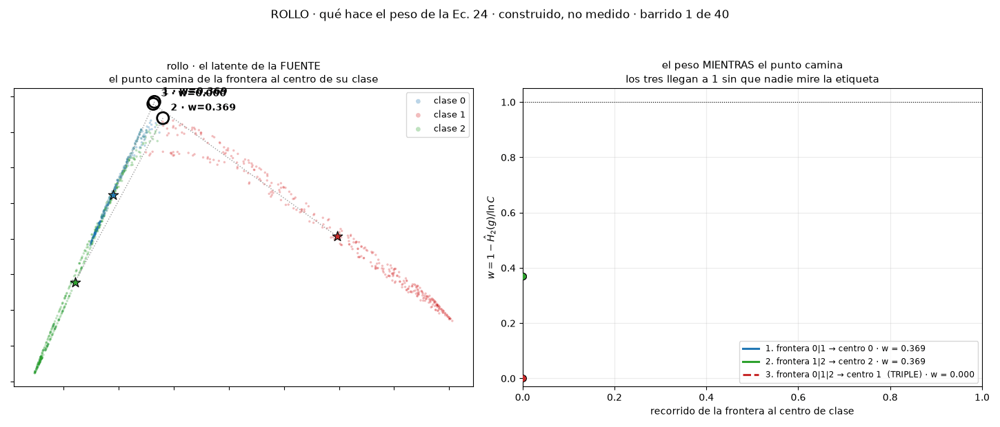

In [25]:
_f = FAMILIAS[2]
_D = datos_semilla(_f, 0)
_enc, _cab, _, _ = fase1_congelada(_f, _D, 'ninguna', 0, HP1['rollo'])
_enc.eval()
with torch.no_grad():
    _H = _enc(_D['Xs_tr']).numpy()
_r = animar_fronteras_w('rollo', _H, _D['ys_tr'].numpy(), _cab,
                        FIGURAS, pasos=40)
print(_r.relative_to(ROOT))
display(Image(filename=str(_r)))


### rollo — la tabla


In [26]:
display(tabla_sopesado_acc(FAMILIAS[2]['nombre'], CONTAM,
                           MODO_REUBICADO, RHO_REPORTADO))


**rollo · 10 semillas · batchnorm (la exige AdaBN, no la elige una comparación) · reubicado · ρ = 0.30 · media ± desvío · azar 0.3333**

| método | época que eligió | acc fuente (test) | acc blanco (test) | vigía final |
|---|---|---|---|---|
| **.predict** | — | — | 0.3528 ± 0.0183 | — |
| **AdaBN** | — | — | 0.6908 ± 0.0525 | — |
| **CREDA sin sopesado** | 90 | 0.9950 ± 0.0030 | 0.8457 ± 0.0438 | 0.6034 ± 0.0643 |
| **CREDA con sopesado** | 97 | 0.9950 ± 0.0030 | 0.8285 ± 0.0715 | 0.5933 ± 0.0749 |

### rollo — los tests declarados


In [27]:
display(tabla_sopesado_test(FAMILIAS[2]['nombre'], CONTAM,
                            MODO_REUBICADO, RHO_REPORTADO))


**rollo · 10 semillas · batchnorm · reubicado · ρ = 0.30 · test, sólo reporte**

| par | con | sin | Δ | IC95 de Δ | t(9) | p | Shapiro p | Wilcoxon p | gana |
|---|---|---|---|---|---|---|---|---|---|
| con sopesado − sin sopesado | 0.8285 | 0.8457 | -0.0172 | [-0.0539, +0.0195] | -1.061 | 0.3165 | 0.0008 | 1.0000 | 5/10 |

`Δ = con sopesado − sin sopesado`, así que **Δ>0 quiere decir que gana el sopesado** · los dos brazos difieren SOLO en la bandera del peso · t pareado, Shapiro-Wilk sobre las diferencias pareadas, Wilcoxon al lado